# Proyek Analisis Data: Bike Sharing Dataset
- **Nama:** Muhammad Faiz Arrozaq
- **Email:** ds296b6y1136@student.devacademy.id
- **ID Dicoding:** mfaizarrozaq

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

- **Pertanyaan 1:** Bagaimana pola jam puncak (peak hours) penyewaan sepeda pada hari kerja dibanding hari libur berdasarkan tipe pengguna (casual vs registered) pada periode 2011–2012?
- **Pertanyaan 2:**  Bagaimana pengaruh musim dan kondisi cuaca terhadap total volume penyewaan sepeda harian pada periode 2011–2012?

## Import Semua Packages/Library yang Digunakan

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Data Wrangling

### Gathering Data

### Memuat Dataset Bike Sharing

Dataset yang digunakan adalah Bike Sharing. Dataset terdiri dari dua file utama, yaitu:

- day.csv: Berisi data penyewaan sepeda berdasarkan tanggal atau harian.
- hour.csv: Berisi data penyewaan sepeda berdasarkan jam.

Load DF


In [2]:
url_day = "https://drive.google.com/uc?id=1i4jdEKOAIAcNdfWZacX_YYHhRF8vyxtZ"
url_hour = "https://drive.google.com/uc?id=1ZWm8GdwjP-9Kq8M-dYO9T6IkYXskilpa"

df_day = pd.read_csv(url_day)
df_hour = pd.read_csv(url_hour)

print(f"\nDATASET DAY \n{df_day.head()}\n")
print(f"\nDATASET HOUR \n{df_hour.head()}\n")


DATASET DAY 
   instant      dteday  season  yr  mnth  holiday  weekday  workingday  \
0        1  2011-01-01       1   0     1        0        6           0   
1        2  2011-01-02       1   0     1        0        0           0   
2        3  2011-01-03       1   0     1        0        1           1   
3        4  2011-01-04       1   0     1        0        2           1   
4        5  2011-01-05       1   0     1        0        3           1   

   weathersit      temp     atemp       hum  windspeed  casual  registered  \
0           2  0.344167  0.363625  0.805833   0.160446     331         654   
1           2  0.363478  0.353739  0.696087   0.248539     131         670   
2           1  0.196364  0.189405  0.437273   0.248309     120        1229   
3           1  0.200000  0.212122  0.590435   0.160296     108        1454   
4           1  0.226957  0.229270  0.436957   0.186900      82        1518   

    cnt  
0   985  
1   801  
2  1349  
3  1562  
4  1600  


DATASET HO

**Insight:** (Opsional)
- Kedua data ini mencatat informasi yang sama persis (tanggal, musim, cuaca, hingga jumlah penyewa). Bedanya, data hour mencatat transaksi secara detail per jam (karena punya kolom hr), sedangkan data day langsung merangkum total penyewaan per hari.
- Informasi seperti musim dan cuaca diwakili pakai kode angka (misalnya angka 1 atau 2), sementara suhu dan kecepatan angin ditulis dalam bentuk desimal (antara 0 sampai 1). Selain itu, dari data awal terlihat kalau total penyewaan (cnt) jauh lebih banyak berasal dari pelanggan yang sudah daftar member (registered) dibanding penyewa biasa/lepas (casual).

### Assessing Data

#### Identifying ... problem

In [3]:
# 1. Cek informasi struktur & tipe data
print("=== INFO DATASET DAY ===")
df_day.info()
print("\n=== INFO DATASET HOUR ===")
df_hour.info()

# 2. Cek missing values & data duplikat
print("\n=== CEK MISSING VALUES & DUPLIKAT ===")
print(f"Missing values df_day : {df_day.isna().sum().sum()}")
print(f"Duplicate data df_day : {df_day.duplicated().sum()}")
print(f"Missing values df_hour: {df_hour.isna().sum().sum()}")
print(f"Duplicate data df_hour: {df_hour.duplicated().sum()}")

# 3. Cek statistik deskriptif (untuk melihat keanehan nilai min/max)
print("\n=== STATISTIK DESKRIPTIF DAY ===")
display(df_day.describe())
print("\n=== STATISTIK DESKRIPTIF HOUR ===")
display(df_hour.describe())

# 4. Cek nilai tidak akurat (kelembapan & kecepatan angin bernilai 0)
print("\n=== CEK INACCURATE VALUE ===")
print("Jumlah hum == 0 di df_day :", (df_day['hum'] == 0).sum())
print("Jumlah hum == 0 di df_hour:", (df_hour['hum'] == 0).sum())
print("Jumlah windspeed == 0 di df_hour:", (df_hour['windspeed'] == 0).sum())

# 5. Cek jumlah outlier menggunakan metode IQR
def cek_outlier(df, nama_df):
    print(f"\n=== CEK OUTLIER ({nama_df}) ===")
    kolom_numerik = ['temp', 'atemp', 'hum', 'windspeed', 'casual', 'registered', 'cnt']
    for col in kolom_numerik:
        Q1 = df[col].quantile(0.25)
        Q3 = df[col].quantile(0.75)
        IQR = Q3 - Q1
        batas_bawah = Q1 - 1.5 * IQR
        batas_atas = Q3 + 1.5 * IQR
        jumlah_outlier = ((df[col] < batas_bawah) | (df[col] > batas_atas)).sum()
        print(f"{col:<10}: {jumlah_outlier} outlier")

cek_outlier(df_day, "df_day")
cek_outlier(df_hour, "df_hour")

=== INFO DATASET DAY ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    object 
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), object(1)
memory usage: 91.5+ KB

=== INFO DATASET HOUR ===
<class 'pandas.core.frame.DataFrame'>
Ran

,instant,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000
mean,366.000000,2.496580,0.500684,6.519836,0.028728,2.997264,0.683995,1.395349,0.495385,0.474354,0.627894,0.190486,848.176471,3656.172367,4504.348837
std,211.165812,1.110807,0.500342,3.451913,0.167155,2.004787,0.465233,0.544894,0.183051,0.162961,0.142429,0.077498,686.622488,1560.256377,1937.211452
min,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.059130,0.079070,0.000000,0.022392,2.000000,20.000000,22.000000
25%,183.500000,2.000000,0.000000,4.000000,0.000000,1.000000,0.000000,1.000000,0.337083,0.337842,0.520000,0.134950,315.500000,2497.000000,3152.000000
50%,366.000000,3.000000,1.000000,7.000000,0.000000,3.000000,1.000000,1.000000,0.498333,0.486733,0.626667,0.180975,713.000000,3662.000000,4548.000000
75%,548.500000,3.000000,1.000000,10.000000,0.000000,5.000000,1.000000,2.000000,0.655417,0.608602,0.730209,0.233214,1096.000000,4776.500000,5956.000000
max,731.000000,4.000000,1.000000,12.000000,1.000000,6.000000,1.000000,3.000000,0.861667,0.840896,0.972500,0.507463,3410.000000,6946.000000,8714.000000



=== STATISTIK DESKRIPTIF HOUR ===


,instant,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,17379.0000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000
mean,8690.0000,2.501640,0.502561,6.537775,11.546752,0.028770,3.003683,0.682721,1.425283,0.496987,0.475775,0.627229,0.190098,35.676218,153.786869,189.463088
std,5017.0295,1.106918,0.500008,3.438776,6.914405,0.167165,2.005771,0.465431,0.639357,0.192556,0.171850,0.192930,0.122340,49.305030,151.357286,181.387599
min,1.0000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.020000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,4345.5000,2.000000,0.000000,4.000000,6.000000,0.000000,1.000000,0.000000,1.000000,0.340000,0.333300,0.480000,0.104500,4.000000,34.000000,40.000000
50%,8690.0000,3.000000,1.000000,7.000000,12.000000,0.000000,3.000000,1.000000,1.000000,0.500000,0.484800,0.630000,0.194000,17.000000,115.000000,142.000000
75%,13034.5000,3.000000,1.000000,10.000000,18.000000,0.000000,5.000000,1.000000,2.000000,0.660000,0.621200,0.780000,0.253700,48.000000,220.000000,281.000000
max,17379.0000,4.000000,1.000000,12.000000,23.000000,1.000000,6.000000,1.000000,4.000000,1.000000,1.000000,1.000000,0.850700,367.000000,886.000000,977.000000



=== CEK INACCURATE VALUE ===
Jumlah hum == 0 di df_day : 1
Jumlah hum == 0 di df_hour: 22
Jumlah windspeed == 0 di df_hour: 2180

=== CEK OUTLIER (df_day) ===
temp      : 0 outlier
atemp     : 0 outlier
hum       : 2 outlier
windspeed : 13 outlier
casual    : 44 outlier
registered: 0 outlier
cnt       : 0 outlier

=== CEK OUTLIER (df_hour) ===
temp      : 0 outlier
atemp     : 0 outlier
hum       : 22 outlier
windspeed : 342 outlier
casual    : 1192 outlier
registered: 680 outlier
cnt       : 505 outlier


**Steps to Take:**
- Memeriksa informasi struktur dan tipe data pada setiap kolom untuk memastikan kesesuaiannya.
- Mengidentifikasi jumlah nilai kosong (*missing value*) pada setiap kolom.
- Memeriksa keberadaan data duplikat pada dataset.
- Menganalisis ringkasan statistik deskriptif untuk mengecek kewajaran distribusi nilai minimum dan maksimum.
- Mengidentifikasi nilai tidak akurat (*inaccurate value*), seperti angka nol pada kolom kelembapan udara dan kecepatan angin.
- Mendeteksi keberadaan pencilan (*outlier*) pada variabel numerik menggunakan metode *Interquartile Range* (IQR).

**Insight:** (Opsional)
- `df_day` maupun `df_hour` memiliki 0 *missing value* dan 0 data duplikat, sehingga seluruh riwayat transaksi penyewaan sepeda selama 2011–2012 tercatat lengkap dan tidak ada baris data yang perlu dihapus.
- Kolom tanggal (`dteday`) masih terbaca sebagai teks biasa (`object`), variabel kategori masih berupa kode angka, dan ditemukan nilai tidak wajar (`0.0`) pada kelembapan udara, sedangkan *outlier* pada jumlah penyewa merupakan lonjakan permintaan asli di jam sibuk atau hari libur sehingga tetap dipertahankan.

### Cleaning Data

Menyalin dataset asli (df_day dan df_hour) ke variabel baru agar data mentah tetap aman.

In [4]:
df_day_clean = df_day.copy()
df_hour_clean = df_hour.copy()

Menghapus kolom instant


In [5]:
df_day_clean.drop(columns=['instant'], inplace=True)
df_hour_clean.drop(columns=['instant'], inplace=True)

Mengubah tipe data kolom 'dteday' menjadi datetime

In [6]:
df_day_clean['dteday'] = pd.to_datetime(df_day_clean['dteday'])
df_hour_clean['dteday'] = pd.to_datetime(df_hour_clean['dteday'])

Mapping kode angka menjadi label kata-kata yang jelas

In [7]:
season_map = {1: 'Spring', 2: 'Summer', 3: 'Fall', 4: 'Winter'}
yr_map = {0: 2011, 1: 2012}
mnth_map = {
    1: 'Jan', 2: 'Feb', 3: 'Mar', 4: 'Apr', 5: 'May', 6: 'Jun',
    7: 'Jul', 8: 'Aug', 9: 'Sep', 10: 'Oct', 11: 'Nov', 12: 'Dec'
}
weekday_map = {
    0: 'Minggu', 1: 'Senin', 2: 'Selasa', 3: 'Rabu',
    4: 'Kamis', 5: 'Jumat', 6: 'Sabtu'
}
workingday_map = {0: 'Akhir Pekan / Libur', 1: 'Hari Kerja'}
weather_map = {
    1: 'Cerah / Berawan',
    2: 'Berkabut / Mendung',
    3: 'Hujan / Salju Ringan',
    4: 'Cuaca Ekstrem'
}

for df in [df_day_clean, df_hour_clean]:
    df['season'] = df['season'].map(season_map)
    df['yr'] = df['yr'].map(yr_map)
    df['mnth'] = df['mnth'].map(mnth_map)
    df['weekday'] = df['weekday'].map(weekday_map)
    df['workingday'] = df['workingday'].map(workingday_map)
    df['weathersit'] = df['weathersit'].map(weather_map)

Mengganti nilai hum == 0 dengan nilai median

In [8]:
for df in [df_day_clean, df_hour_clean]:
    df['hum'] = df['hum'].replace(0, np.nan)
    df['hum'] = df['hum'].fillna(df['hum'].median())

Verifikasi hasil cleaning // print hasil clean

In [9]:
print("=== HASIL CLEANING DF_DAY ===")
print(df_day_clean.dtypes)
print(f"Nilai minimum hum: {df_day_clean['hum'].min():.4f} | Missing values: {df_day_clean.isna().sum().sum()}")
display(df_day_clean.head(3))

print("\n=== HASIL CLEANING DF_HOUR ===")
print(df_hour_clean.dtypes)
print(f"Nilai minimum hum: {df_hour_clean['hum'].min():.4f} | Missing values: {df_hour_clean.isna().sum().sum()}")
display(df_hour_clean.head(3))

=== HASIL CLEANING DF_DAY ===
dteday        datetime64[ns]
season                object
yr                     int64
mnth                  object
holiday                int64
weekday               object
workingday            object
weathersit            object
temp                 float64
atemp                float64
hum                  float64
windspeed            float64
casual                 int64
registered             int64
cnt                    int64
dtype: object
Nilai minimum hum: 0.1879 | Missing values: 0


,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,2011-01-01,Spring,2011,Jan,0,Sabtu,Akhir Pekan / Libur,Berkabut / Mendung,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2011-01-02,Spring,2011,Jan,0,Minggu,Akhir Pekan / Libur,Berkabut / Mendung,0.363478,0.353739,0.696087,0.248539,131,670,801
2,2011-01-03,Spring,2011,Jan,0,Senin,Hari Kerja,Cerah / Berawan,0.196364,0.189405,0.437273,0.248309,120,1229,1349



=== HASIL CLEANING DF_HOUR ===
dteday        datetime64[ns]
season                object
yr                     int64
mnth                  object
hr                     int64
holiday                int64
weekday               object
workingday            object
weathersit            object
temp                 float64
atemp                float64
hum                  float64
windspeed            float64
casual                 int64
registered             int64
cnt                    int64
dtype: object
Nilai minimum hum: 0.0800 | Missing values: 0


,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,2011-01-01,Spring,2011,Jan,0,0,Sabtu,Akhir Pekan / Libur,Cerah / Berawan,0.24,0.2879,0.81,0.0,3,13,16
1,2011-01-01,Spring,2011,Jan,1,0,Sabtu,Akhir Pekan / Libur,Cerah / Berawan,0.22,0.2727,0.80,0.0,8,32,40
2,2011-01-01,Spring,2011,Jan,2,0,Sabtu,Akhir Pekan / Libur,Cerah / Berawan,0.22,0.2727,0.80,0.0,5,27,32


**Steps to Take:**

- Menyalin dataset asli (df_day dan df_hour) ke variabel baru agar data mentah tetap aman.

- Menghapus kolom instant karena hanya berfungsi sebagai nomor indeks baris.

- Mengubah tipe data kolom dteday dari object menjadi datetime.

- Mengubah kode angka pada kolom kategorikal (season, yr, mnth, weekday, workingday, dan weathersit) menjadi label teks yang deskriptif.

- Mengganti nilai tidak akurat (0.0) pada kolom kelembapan udara (hum) dengan nilai median agar distribusi data tetap realistis.

- Memeriksa kembali struktur tipe data dan ringkasan nilai setelah pembersihan untuk memastikan data siap dianalisis.

**Insight:** (Opsional)
- Seluruh kode angka pada musim, bulan, hari, hingga cuaca sudah diubah menjadi label teks, format tanggal sudah memakai label (datetime), dan jumlah total baris tetap utuh (731 baris harian dan 17.379 baris per jam).

- Nilai kelembapan udara (hum) yang tadinya bernilai 0.0 (mustahil terjadi secara alami) kini sudah diperbaiki menggunakan nilai tengah (median), sehingga nilai minimumnya kembali realistis (0.1879 di data harian dan 0.08 di data per jam) dan seluruh data siap masuk ke tahap eksplorasi (EDA).

## Exploratory Data Analysis (EDA)

### Pertanyaan 1 : Bagaimana pola jam puncak (peak hours) penyewaan sepeda pada hari kerja dibanding hari libur berdasarkan tipe pengguna (casual vs registered) pada periode 2011–2012?

In [10]:
print("=== RATA-RATA PENYEWAAN PER JAM: HARI KERJA VS LIBUR ===")
eda_jam = df_hour_clean.groupby(['workingday', 'hr'])[['casual', 'registered', 'cnt']].mean().round(1)
display(eda_jam)

print("\n=== TOP 5 JAM TERSIBUK DI HARI KERJA ===")
display(eda_jam.loc['Hari Kerja'].sort_values(by='cnt', ascending=False).head(5))

print("\n=== TOP 5 JAM TERSIBUK DI AKHIR PEKAN / LIBUR ===")
display(eda_jam.loc['Akhir Pekan / Libur'].sort_values(by='cnt', ascending=False).head(5))

=== RATA-RATA PENYEWAAN PER JAM: HARI KERJA VS LIBUR ===


casual  registered    cnt
workingday          hr                           
Akhir Pekan / Libur 0     16.6        74.2   90.8
                    1     12.5        57.0   69.5
                    2     10.4        42.8   53.2
                    3      6.5        19.3   25.8
                    4      2.3         6.0    8.3
                    5      1.7         7.0    8.7
                    6      3.8        14.9   18.7
                    7      8.6        34.8   43.4
                    8     20.4        85.2  105.7
                    9     45.0       126.6  171.6
                    10    79.3       176.6  255.9
                    11   106.7       208.7  315.3
                    12   126.2       240.0  366.3
                    13   136.4       236.3  372.7
                    14   139.6       225.1  364.6
                    15   136.5       222.3  358.8
                    16   128.6       224.1  352.7
                    17   111.8       211.7  323.5
                    18    84.2       196.8  281.1
                    19    65.5       166.1  231.7
                    20    46.8       128.0  174.7
                    21    36.1       105.9  142.1
                    22    28.1        88.0  116.1
                    23    19.1        66.8   85.9
Hari Kerja          0      7.1        29.6   36.8
                    1      3.7        12.8   16.6
                    2      2.1         6.5    8.7
                    3      0.9         4.0    4.9
                    4      0.8         4.7    5.4
                    5      1.3        23.6   24.9
                    6      4.3        98.2  102.5
                    7     12.2       278.4  290.6
                    8     22.3       454.7  477.0
                    9     24.3       217.2  241.5
                    10    31.2       104.2  135.4
                    11    37.6       120.6  158.2
                    12    41.4       159.5  200.8
                    13    42.6       155.9  198.4
                    14    45.9       137.7  183.6
                    15    46.3       155.0  201.3
                    16    48.3       244.8  293.1
                    17    56.9       468.4  525.3
                    18    50.5       441.8  492.2
                    19    41.0       307.4  348.4
                    20    31.4       218.3  249.7
                    21    24.6       161.7  186.3
                    22    19.6       118.8  138.4
                    23    13.4        75.3   88.7


=== TOP 5 JAM TERSIBUK DI HARI KERJA ===


,casual,registered,cnt
hr,,,
17,56.9,468.4,525.3
18,50.5,441.8,492.2
8,22.3,454.7,477.0
19,41.0,307.4,348.4
16,48.3,244.8,293.1



=== TOP 5 JAM TERSIBUK DI AKHIR PEKAN / LIBUR ===


,casual,registered,cnt
hr,,,
13,136.4,236.3,372.7
12,126.2,240.0,366.3
14,139.6,225.1,364.6
15,136.5,222.3,358.8
16,128.6,224.1,352.7


### Pertanyaan 2 : Bagaimana pengaruh musim dan kondisi cuaca terhadap total volume penyewaan sepeda harian pada periode 2011–2012?

In [11]:
print("\n=== VOLUME PENYEWAAN HARIAN BERDASARKAN MUSIM ===")
eda_musim = df_day_clean.groupby('season').agg(
    jumlah_hari=('cnt', 'count'),
    rata_rata_harian=('cnt', 'mean'),
    total_penyewaan=('cnt', 'sum'),
    rata_rata_casual=('casual', 'mean'),
    rata_rata_registered=('registered', 'mean')
).round(1).sort_values(by='rata_rata_harian', ascending=False)
display(eda_musim)

print("\n=== VOLUME PENYEWAAN HARIAN BERDASARKAN CUACA ===")
eda_cuaca = df_day_clean.groupby('weathersit').agg(
    jumlah_hari=('cnt', 'count'),
    rata_rata_harian=('cnt', 'mean'),
    total_penyewaan=('cnt', 'sum'),
    rata_rata_casual=('casual', 'mean'),
    rata_rata_registered=('registered', 'mean')
).round(1).sort_values(by='rata_rata_harian', ascending=False)
display(eda_cuaca)

print("\n=== RATA-RATA PENYEWAAN HARIAN: KOMBINASI MUSIM & CUACA ===")
eda_musim_cuaca = df_day_clean.pivot_table(
    index='season',
    columns='weathersit',
    values='cnt',
    aggfunc='mean'
).round(1)
display(eda_musim_cuaca)


=== VOLUME PENYEWAAN HARIAN BERDASARKAN MUSIM ===


,jumlah_hari,rata_rata_harian,total_penyewaan,rata_rata_casual,rata_rata_registered
season,,,,,
Fall,188,5644.3,1061129,1202.6,4441.7
Summer,184,4992.3,918589,1106.1,3886.2
Winter,178,4728.2,841613,729.1,3999.1
Spring,181,2604.1,471348,334.9,2269.2



=== VOLUME PENYEWAAN HARIAN BERDASARKAN CUACA ===


,jumlah_hari,rata_rata_harian,total_penyewaan,rata_rata_casual,rata_rata_registered
weathersit,,,,,
Cerah / Berawan,463,4876.8,2257952,964.0,3912.8
Berkabut / Mendung,247,4035.9,996858,687.4,3348.5
Hujan / Salju Ringan,21,1803.3,37869,185.5,1617.8



=== RATA-RATA PENYEWAAN HARIAN: KOMBINASI MUSIM & CUACA ===


weathersit,Berkabut / Mendung,Cerah / Berawan,Hujan / Salju Ringan
season,,,
Fall,5222.5,5878.3,2751.8
Spring,2357.2,2811.1,934.8
Summer,4236.7,5548.5,1169.0
Winter,4654.0,5043.6,1961.6


**Insight:** (Opsional)
- Pertanyaan 1
  - Pada hari kerja, penyewaan sepeda memuncak di dua waktu utama, yaitu pagi pukul 08.00 dan sore pukul 17.00–18.00. Lonjakan ini didominasi oleh pelanggan member (registered), yang menunjukkan bahwa sepeda dipakai sebagai transportasi rutin untuk berangkat dan pulang kerja atau sekolah.

  - Pada akhir pekan dan hari libur, tidak ada lonjakan pagi dan sore. Penyewaan justru ramai secara bertahap di siang hingga sore hari (pukul 12.00–16.00) dengan lonjakan tajam dari penyewa biasa/lepas (casual), menandakan sepeda dipakai untuk jalan-jalan santai atau rekreasi.

- Pertanyaan 2
  - Berdasarkan musim, penyewaan harian paling ramai terjadi saat musim gugur (Fall), disusul musim panas (Summer), lalu musim dingin (Winter), dan paling sepi pada musim semi (Spring) karena suhu yang masih dingin di awal tahun.

  - Berdasarkan cuaca, pelanggan paling banyak menyewa sepeda saat cuaca Cerah / Berawan, mulai berkurang saat Berkabut / Mendung, dan anjlok drastis ketika Hujan / Salju Ringan (bahkan nyaris tidak ada penyewaan sama sekali saat Cuaca Ekstrem).

## Visualization & Explanatory Analysis

### Pertanyaan 1:

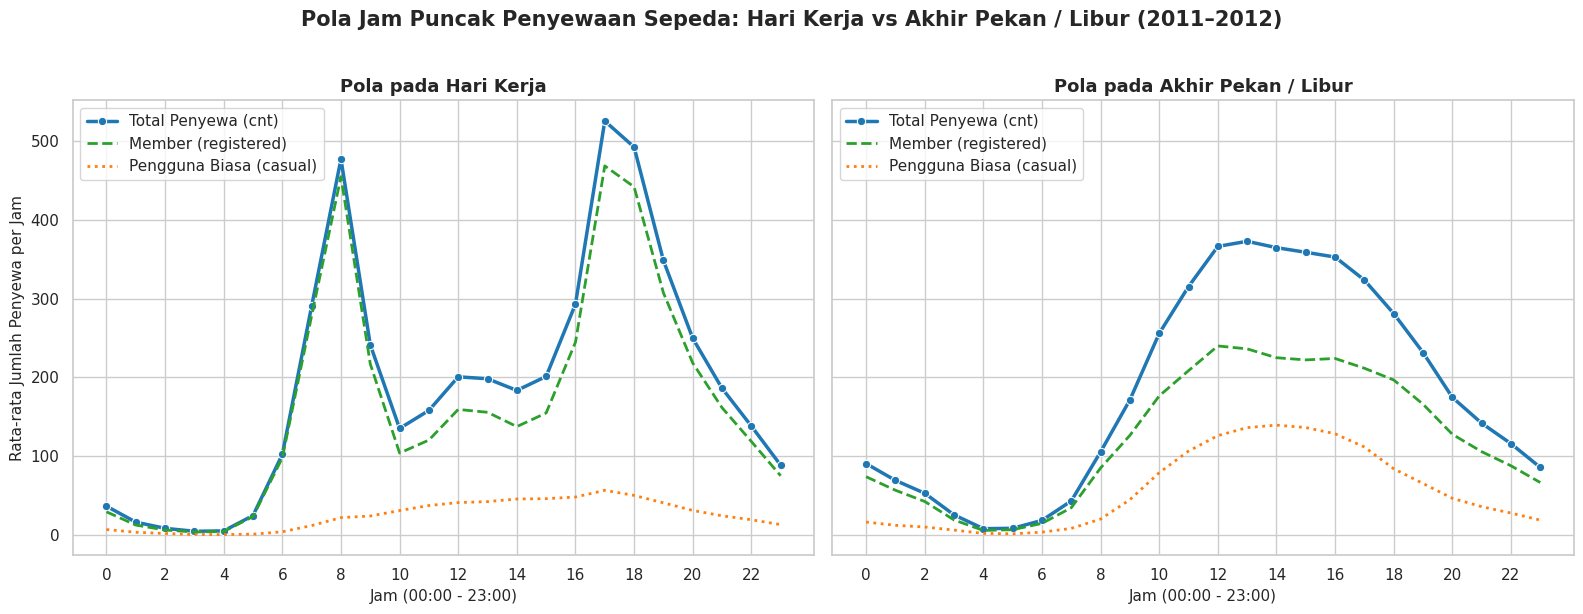

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharey=True)
fig.suptitle('Pola Jam Puncak Penyewaan Sepeda: Hari Kerja vs Akhir Pekan / Libur (2011–2012)',
             fontsize=15, fontweight='bold', y=1.02)

kategori_hari = ['Hari Kerja', 'Akhir Pekan / Libur']

for idx, kategori in enumerate(kategori_hari):
    data_subset = df_hour_clean[df_hour_clean['workingday'] == kategori]
    hourly_avg = data_subset.groupby('hr')[['registered', 'casual', 'cnt']].mean().reset_index()

    ax = axes[idx]
    sns.lineplot(data=hourly_avg, x='hr', y='cnt', ax=ax, label='Total Penyewa (cnt)', color='#1f77b4', linewidth=2.5, marker='o')
    sns.lineplot(data=hourly_avg, x='hr', y='registered', ax=ax, label='Member (registered)', color='#2ca02c', linewidth=2, linestyle='--')
    sns.lineplot(data=hourly_avg, x='hr', y='casual', ax=ax, label='Pengguna Biasa (casual)', color='#ff7f0e', linewidth=2, linestyle=':')

    ax.set_title(f'Pola pada {kategori}', fontsize=13, fontweight='bold')
    ax.set_xlabel('Jam (00:00 - 23:00)', fontsize=11)
    ax.set_xticks(range(0, 24, 2))
    if idx == 0:
        ax.set_ylabel('Rata-rata Jumlah Penyewa per Jam', fontsize=11)
    ax.legend(loc='upper left')

plt.tight_layout()
plt.show()

### Pertanyaan 2:

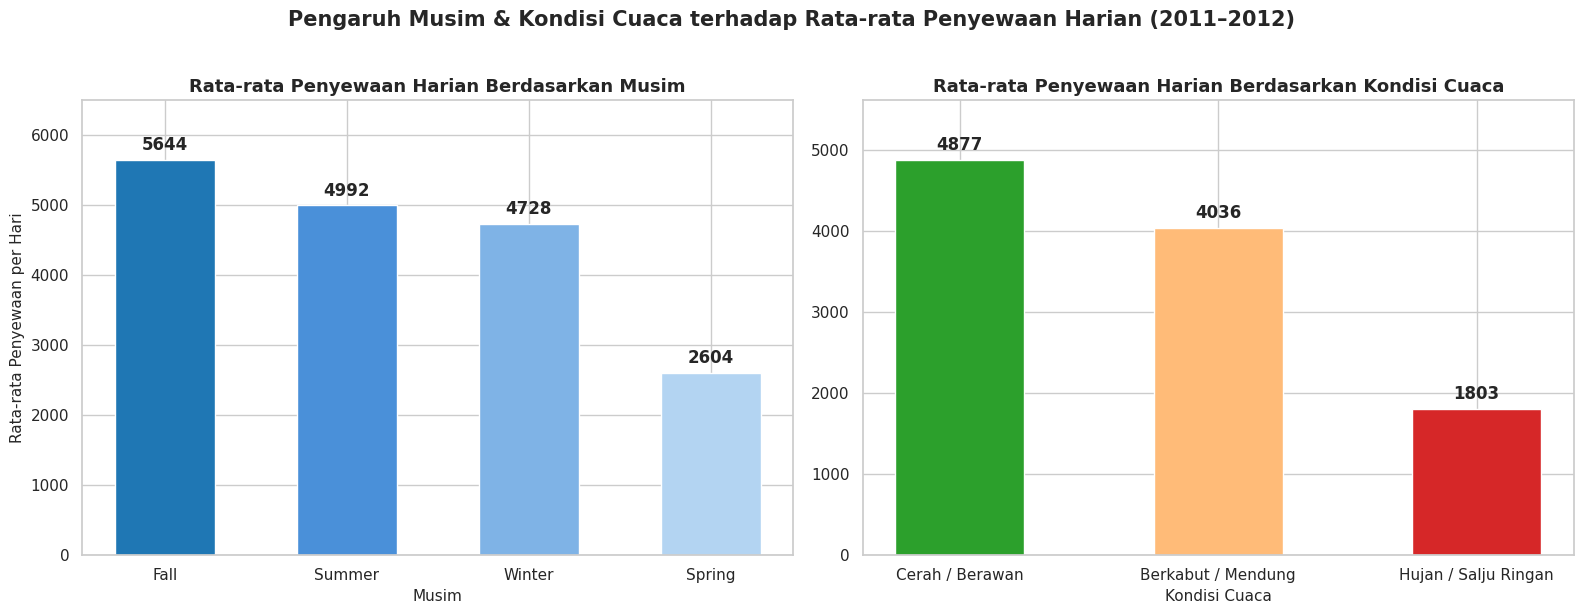

In [13]:
# Visualisasi 2: Menjawab Pertanyaan 2 (Pengaruh Musim & Kondisi Cuaca terhadap Volume Penyewaan Harian)
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle('Pengaruh Musim & Kondisi Cuaca terhadap Rata-rata Penyewaan Harian (2011–2012)',
             fontsize=15, fontweight='bold', y=1.02)

# Subplot 1: Berdasarkan Musim
urutan_musim = ['Fall', 'Summer', 'Winter', 'Spring']
musim_avg = df_day_clean.groupby('season')['cnt'].mean().reindex(urutan_musim).reset_index()
warna_musim = ['#1f77b4', '#4a90d9', '#7fb3e6', '#b3d4f2']

bars1 = axes[0].bar(musim_avg['season'], musim_avg['cnt'], color=warna_musim, width=0.55)
axes[0].set_title('Rata-rata Penyewaan Harian Berdasarkan Musim', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Musim', fontsize=11)
axes[0].set_ylabel('Rata-rata Penyewaan per Hari', fontsize=11)
axes[0].bar_label(bars1, fmt='%.0f', padding=4, fontweight='bold')
axes[0].set_ylim(0, musim_avg['cnt'].max() * 1.15)

# Subplot 2: Berdasarkan Kondisi Cuaca
urutan_cuaca = ['Cerah / Berawan', 'Berkabut / Mendung', 'Hujan / Salju Ringan']
cuaca_avg = df_day_clean.groupby('weathersit')['cnt'].mean().reindex(urutan_cuaca).reset_index()
warna_cuaca = ['#2ca02c', '#ffbb78', '#d62728']

bars2 = axes[1].bar(cuaca_avg['weathersit'], cuaca_avg['cnt'], color=warna_cuaca, width=0.5)
axes[1].set_title('Rata-rata Penyewaan Harian Berdasarkan Kondisi Cuaca', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Kondisi Cuaca', fontsize=11)
axes[1].bar_label(bars2, fmt='%.0f', padding=4, fontweight='bold')
axes[1].set_ylim(0, cuaca_avg['cnt'].max() * 1.15)

plt.tight_layout()
plt.show()

In [14]:
# 1. Detail jumlah & proporsi pengguna pada jam puncak (Pertanyaan 1)
peak_kerja = df_hour_clean[(df_hour_clean['workingday'] == 'Hari Kerja') & (df_hour_clean['hr'].isin([8, 17]))].groupby('hr')[['registered', 'casual', 'cnt']].mean()
peak_kerja['proporsi_registered (%)'] = (peak_kerja['registered'] / peak_kerja['cnt'] * 100).round(1)
peak_kerja['proporsi_casual (%)'] = (peak_kerja['casual'] / peak_kerja['cnt'] * 100).round(1)

peak_libur = df_hour_clean[(df_hour_clean['workingday'] == 'Akhir Pekan / Libur') & (df_hour_clean['hr'].isin([12, 13, 14, 15]))][['registered', 'casual', 'cnt']].mean()

print("=== JAM PUNCAK HARI KERJA (08.00 & 17.00) ===")
display(peak_kerja.round(1))
print(f"\n=== RATA-RATA JAM PUNCAK AKHIR PEKAN (12.00–15.00) ===")
print(f"Total: {peak_libur['cnt']:.1f} | Registered: {peak_libur['registered']:.1f} ({peak_libur['registered']/peak_libur['cnt']*100:.1f}%) | Casual: {peak_libur['casual']:.1f} ({peak_libur['casual']/peak_libur['cnt']*100:.1f}%)")

# 2. Detail rata-rata harian & persentase selisih musim dan cuaca (Pertanyaan 2)
musim_summary = df_day_clean.groupby('season')['cnt'].agg(rata_rata_harian='mean', total_penyewaan='sum').reindex(['Fall', 'Summer', 'Winter', 'Spring'])
cuaca_summary = df_day_clean.groupby('weathersit')['cnt'].agg(rata_rata_harian='mean', total_penyewaan='sum').reindex(['Cerah / Berawan', 'Berkabut / Mendung', 'Hujan / Salju Ringan'])

print("\n=== RINGKASAN MUSIM ===")
display(musim_summary.round(0))
print("\n=== RINGKASAN CUACA ===")
display(cuaca_summary.round(0))

=== JAM PUNCAK HARI KERJA (08.00 & 17.00) ===


,registered,casual,cnt,proporsi_registered (%),proporsi_casual (%)
hr,,,,,
8,454.7,22.3,477.0,95.3,4.7
17,468.4,56.9,525.3,89.2,10.8



=== RATA-RATA JAM PUNCAK AKHIR PEKAN (12.00–15.00) ===
Total: 365.6 | Registered: 230.9 (63.2%) | Casual: 134.7 (36.8%)

=== RINGKASAN MUSIM ===


,rata_rata_harian,total_penyewaan
season,,
Fall,5644.0,1061129
Summer,4992.0,918589
Winter,4728.0,841613
Spring,2604.0,471348



=== RINGKASAN CUACA ===


,rata_rata_harian,total_penyewaan
weathersit,,
Cerah / Berawan,4877.0,2257952
Berkabut / Mendung,4036.0,996858
Hujan / Salju Ringan,1803.0,37869


**Insight:** (Opsional)

Pertanyaan 1:

1. Pada hari kerja, jam puncak penyewaan tertinggi terjadi dua kali, yaitu pada pagi pukul 08.00 (rentang 07.00–09.00) dan sore pukul 17.00–18.00 (rentang 17.00–19.00).
2. Penyewaan pada hari kerja didominasi oleh pengguna *registered* (member) yang memakai sepeda untuk berangkat dan pulang kerja atau sekolah.
3. Pada akhir pekan dan hari libur, lonjakan penyewaan bergeser ke siang hingga sore hari pada pukul 11.00–16.00.
4. Jumlah pengguna *casual* (penyewa biasa) meningkat tajam pada hari libur karena sepeda lebih banyak digunakan untuk rekreasi.
5. Jam dengan intensitas penyewaan terendah terjadi pada dini hari pukul 00.00–05.00, baik di hari kerja maupun hari libur.

Pertanyaan 2:

1. Musim gugur (*Fall*) merupakan puncak penyewaan sepeda tertinggi dengan rata-rata 5.644 penyewaan per hari.
2. Musim panas (*Summer*) menempati posisi tertinggi kedua (4.992 penyewaan/hari), disusul musim dingin (*Winter*) di posisi ketiga (4.728 penyewaan/hari).
3. Musim semi (*Spring*) merupakan musim dengan rata-rata penyewaan terendah (2.604 penyewaan/hari).
4. Berdasarkan kondisi cuaca, penyewaan harian tertinggi terjadi saat cuaca cerah atau berawan dengan rata-rata 4.877 penyewaan per hari.
5. Volume penyewaan menurun saat cuaca berkabut atau mendung (4.036 penyewaan/hari) dan anjlok drastis ketika terjadi hujan atau salju ringan (1.803 penyewaan/hari).

## Analisis Lanjutan (Opsional)

Manual Grouping / Clustering Berdasarkan Segmen Waktu

workingday,Akhir Pekan / Libur,Hari Kerja
klaster_waktu,,
Dini Hari (00:00–05:00),43.0,16.4
Pagi (06:00–10:00),119.2,249.4
Siang (11:00–14:00),354.7,185.3
Sore (15:00–18:00),329.1,378.0
Malam (19:00–23:00),150.1,202.3


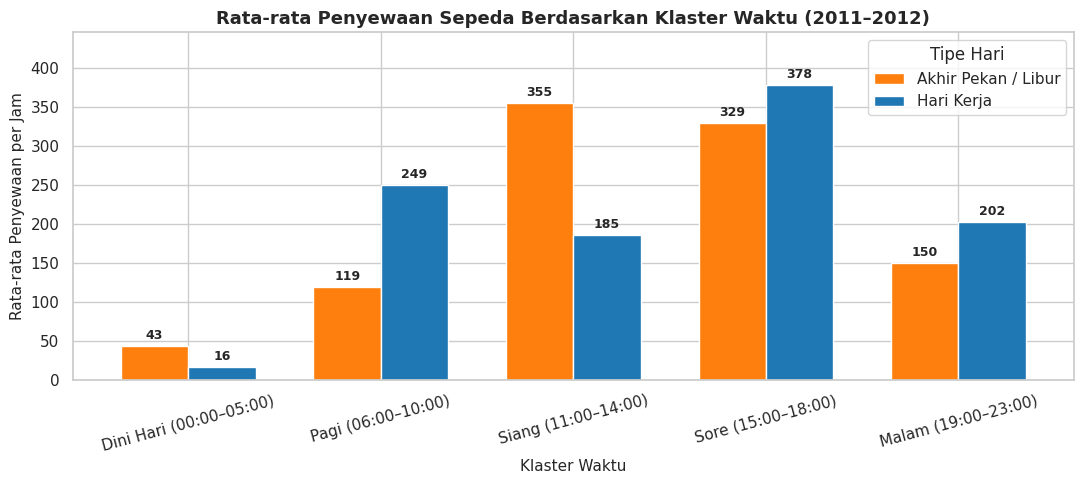

In [15]:
def kategori_waktu(hr):
    if 0 <= hr <= 5:
        return 'Dini Hari (00:00–05:00)'
    elif 6 <= hr <= 10:
        return 'Pagi (06:00–10:00)'
    elif 11 <= hr <= 14:
        return 'Siang (11:00–14:00)'
    elif 15 <= hr <= 18:
        return 'Sore (15:00–18:00)'
    else:
        return 'Malam (19:00–23:00)'

df_hour_clean['klaster_waktu'] = df_hour_clean['hr'].apply(kategori_waktu)

urutan_waktu = [
    'Dini Hari (00:00–05:00)',
    'Pagi (06:00–10:00)',
    'Siang (11:00–14:00)',
    'Sore (15:00–18:00)',
    'Malam (19:00–23:00)'
]

cluster_waktu = (
    df_hour_clean.groupby(['klaster_waktu', 'workingday'])['cnt']
    .mean()
    .unstack()
    .reindex(urutan_waktu)
    .round(1)
)
display(cluster_waktu)

# Visualisasi Hasil Clustering Waktu
ax = cluster_waktu.plot(kind='bar', figsize=(11, 5), color=['#ff7f0e', '#1f77b4'], width=0.7)
plt.title('Rata-rata Penyewaan Sepeda Berdasarkan Klaster Waktu (2011–2012)', fontsize=13, fontweight='bold')
plt.xlabel('Klaster Waktu', fontsize=11)
plt.ylabel('Rata-rata Penyewaan per Jam', fontsize=11)
plt.xticks(rotation=15)
plt.ylim(0, cluster_waktu.max().max() * 1.18)
plt.legend(title='Tipe Hari')

for container in ax.containers:
    ax.bar_label(container, fmt='%.0f', padding=3, fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()

**Insight:** (Opsional)
* Klaster waktu Sore (15:00–18:00) menjadi periode dengan rata-rata penyewaan tertinggi secara keseluruhan, terutama pada hari kerja saat jam pulang kantor/sekolah.
* Pada akhir pekan atau hari libur, aktivitas penyewaan terkonsentrasi penuh pada klaster Siang (11:00–14:00) dan Sore (15:00–18:00), sedangkan pada hari kerja klaster Pagi (06:00–10:00) punya kontribusi yang hampir menyamai jam sore.
* Klaster Dini Hari (00:00–05:00) selalu menjadi periode paling sepi di semua tipe hari sehingga sangat ideal dijadikan jendela waktu operasional untuk pengisian ulang unit sepeda di stasiun.

## Conclusion & Recommendation

### Conclusion

* **Conclusion Pertanyaan 1:**
  Berdasarkan metrik **rata-rata penyewaan per jam**, pola jam puncak (*peak hours*) memiliki perbedaan yang kontras antara hari kerja dan akhir pekan/hari libur:
  * **Hari Kerja:** Penyewaan memuncak dua kali mengikuti jam berangkat dan pulang kerja, yaitu pada **pukul 08.00 pagi** dengan rata-rata **477,0 penyewaan/jam** dan **pukul 17.00 sore** dengan rata-rata **525,3 penyewaan/jam**. Pada kedua jam sibuk tersebut, aktivitas didominasi sangat kuat oleh pengguna **registered (member)** dengan proporsi mencapai **95,3%** (rata-rata **454,7 penyewaan/jam**) pada pukul 08.00 dan **89,2%** (rata-rata **468,4 penyewaan/jam**) pada pukul 17.00 untuk kebutuhan komuter, sedangkan pengguna **casual** hanya berkontribusi sebesar **4,7%** (rata-rata **22,3 penyewaan/jam**) pada pagi hari dan **10,8%** (rata-rata **56,9 penyewaan/jam**) pada sore hari.
  * **Akhir Pekan / Hari Libur:** Lonjakan penyewaan bergeser ke rentang siang hingga sore hari (**pukul 12.00–15.00**) dengan rata-rata **365,6 penyewaan/jam**. Pada periode ini, proporsi pengguna **casual** meningkat drastis hingga mencapai **36,8%** (rata-rata **134,7 penyewaan/jam**), sementara pengguna **registered** berada di proporsi **63,2%** (rata-rata **230,9 penyewaan/jam**) karena sepeda lebih banyak dimanfaatkan untuk aktivitas rekreasi.

* **Conclusion Pertanyaan 2:**
  Berdasarkan metrik **rata-rata penyewaan per hari** (dan didukung total penyewaan keseluruhan selama periode 2011–2012), faktor musim dan kondisi cuaca terbukti memberikan dampak signifikan terhadap fluktuasi volume penyewaan sepeda:
  * **Pengaruh Musim:** Musim gugur (*Fall*) mencatatkan rata-rata penyewaan harian tertinggi sebesar **5.644 penyewaan/hari** (total **1.061.129 penyewaan**), lebih tinggi **13,1%** dibandingkan musim panas (*Summer*) di posisi kedua dengan **4.992 penyewaan/hari** (total **918.589 penyewaan**) dan lebih tinggi **19,4%** dibandingkan musim dingin (*Winter*) di posisi ketiga dengan **4.728 penyewaan/hari** (total **841.613 penyewaan**). Sebaliknya, musim semi (*Spring*) menjadi periode dengan permintaan terendah dengan rata-rata **2.604 penyewaan/hari** (total **471.348 penyewaan**), atau mengalami penurunan sebesar **53,9%** dibandingkan puncak musim gugur (sebaliknya, rata-rata harian musim gugur melonjak **116,7%** dibandingkan musim semi).
  * **Pengaruh Kondisi Cuaca:** Kondisi cuaca cerah atau berawan menghasilkan rata-rata tertinggi sebesar **4.877 penyewaan/hari** (total **2.257.952 penyewaan**). Ketika cuaca berubah menjadi berkabut atau mendung, rata-rata penyewaan harian turun sebesar **17,2%** menjadi **4.036 penyewaan/hari** (total **996.858 penyewaan**), dan anjlok tajam sebesar **63,0%** menjadi hanya **1.803 penyewaan/hari** (total **37.869 penyewaan**) saat terjadi hujan atau salju ringan.

**Rekomendasi Action Item:**
* **Optimasi distribusi stok sepeda berbasis jam dan lokasi:** Pastikan ketersediaan unit sepeda penuh di sekitar stasiun transportasi dan kawasan perkantoran sebelum pukul 07.00 dan 16.30 pada hari kerja, lalu geser alokasi stok lebih banyak ke area taman kota dan tempat wisata pada pukul 10.00–16.00 saat akhir pekan.

* **Promo konversi pengguna *casual* menjadi *registered* di akhir pekan:** Tawarkan paket membership khusus akhir pekan atau diskon langganan pertama bagi penyewa casual yang ramai beraktivitas di siang hari saat musim panas dan musim gugur.

* **Penjadwalan perawatan (*maintenance*) di waktu sepi:** Fokuskan pemeliharaan rutin, perbaikan unit, dan distribusi ulang sepeda pada klaster waktu Dini Hari (00:00–05:00) serta saat Musim Semi (Spring) atau hari hujan agar seluruh armada siap beroperasi maksimal di masa puncak permintaan.